# 01 – Data Loading & Exploratory Data Analysis (EDA)
**CS 7331 Data Mining – Fall 2026 · Project Team Five**
**Author:** Safia Khan
**Project:** Classifying phishing vs. legitimate websites from structural features

## Purpose
This notebook loads the UCI Phishing Websites dataset and explores it before any modeling.

## What this notebook does
1. Mounts Google Drive and downloads the dataset from the UCI ML Repository (id = 327)
2. Saves a copy to `/data/phishing.csv` in our shared folder
3. Checks basic info: shape, data types, missing values
4. Checks class balance (phishing vs. legitimate)
5. Computes summary statistics for all 30 features
6. Plots feature distributions and a correlation heatmap

## Output
- `data/phishing.csv` (raw dataset used by all later notebooks)
- Figures saved to `/figures`
- Numbers for the proposal's Dataset section and the report's Data section

**Source:** https://archive.ics.uci.edu/dataset/327/phishing+websites

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/CS7331_Phishing/data'

Mounted at /content/drive


In [2]:
!pip install ucimlrepo -q

In [3]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

phishing = fetch_ucirepo(id=327)
X = phishing.data.features
y = phishing.data.targets

df = pd.concat([X, y], axis=1)
TARGET = y.columns[0]   # name of the label column

df.to_csv(f'{DATA_DIR}/phishing.csv', index=False)
print("Saved. Target column is:", TARGET)

Saved. Target column is: result


In [4]:
print("Shape (rows, columns):", df.shape)
print("\nMissing values in total:", df.isnull().sum().sum())
print("\nData types:\n", df.dtypes.value_counts())

print("\nClass balance (counts):")
print(df[TARGET].value_counts())
print("\nClass balance (%):")
print((df[TARGET].value_counts(normalize=True) * 100).round(1))

Shape (rows, columns): (11055, 31)

Missing values in total: 0

Data types:
 int64    31
Name: count, dtype: int64

Class balance (counts):
result
 1    6157
-1    4898
Name: count, dtype: int64

Class balance (%):
result
 1    55.7
-1    44.3
Name: proportion, dtype: float64


In [5]:
for col in df.columns:
    print(f"{col:30s} {sorted(df[col].unique())}")

having_ip_address              [np.int64(-1), np.int64(1)]
url_length                     [np.int64(-1), np.int64(0), np.int64(1)]
shortining_service             [np.int64(-1), np.int64(1)]
having_at_symbol               [np.int64(-1), np.int64(1)]
double_slash_redirecting       [np.int64(-1), np.int64(1)]
prefix_suffix                  [np.int64(-1), np.int64(1)]
having_sub_domain              [np.int64(-1), np.int64(0), np.int64(1)]
sslfinal_state                 [np.int64(-1), np.int64(0), np.int64(1)]
domain_registration_length     [np.int64(-1), np.int64(1)]
favicon                        [np.int64(-1), np.int64(1)]
port                           [np.int64(-1), np.int64(1)]
https_token                    [np.int64(-1), np.int64(1)]
request_url                    [np.int64(-1), np.int64(1)]
url_of_anchor                  [np.int64(-1), np.int64(0), np.int64(1)]
links_in_tags                  [np.int64(-1), np.int64(0), np.int64(1)]
sfh                            [np.int64(-1), np.i

## Exploratory Data Analysis

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE = '/content/drive/MyDrive/CS7331_Phishing'
FIG_DIR = f'{BASE}/figures'

df = pd.read_csv(f'{BASE}/data/phishing.csv')
df = df.drop_duplicates().reset_index(drop=True)  # drop the duplicate rows so EDA matches the training data
TARGET = 'result'
FEATURES = [c for c in df.columns if c != TARGET]
print(df.shape)

import os
os.makedirs(FIG_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(5849, 31)


In [7]:
# Share of each value (-1, 0, 1) per feature, split by class
summary = []
for col in FEATURES:
    ct = pd.crosstab(df[col], df[TARGET], normalize='columns').round(3)
    ct.columns = ['phishing_%' if c == -1 else 'legit_%' for c in ct.columns]
    ct['feature'] = col
    ct['value'] = ct.index
    summary.append(ct.reset_index(drop=True))

summary_df = pd.concat(summary)[['feature', 'value', 'phishing_%', 'legit_%']]
summary_df.to_csv(f'{BASE}/data/feature_summary_by_class.csv', index=False)
summary_df.head(15)

,feature,value,phishing_%,legit_%
0,having_ip_address,-1,0.484,0.380
1,having_ip_address,1,0.516,0.620
0,url_length,-1,0.820,0.778
1,url_length,0,0.020,0.013
2,url_length,1,0.160,0.209
0,shortining_service,-1,0.114,0.167
1,shortining_service,1,0.886,0.833
0,having_at_symbol,-1,0.219,0.191
1,having_at_symbol,1,0.781,0.809
0,double_slash_redirecting,-1,0.129,0.154


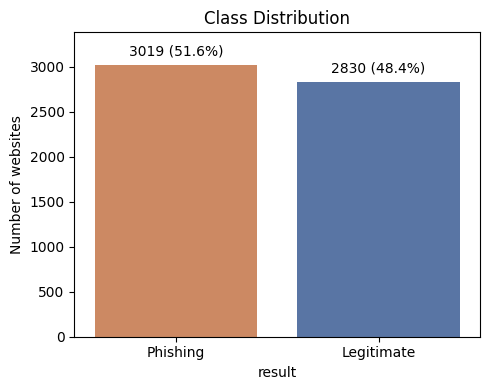

In [11]:
counts = df[TARGET].map({-1: 'Phishing', 1: 'Legitimate'}).value_counts()

plt.figure(figsize=(5, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
                 palette={'Phishing': '#DD8452', 'Legitimate': '#4C72B0'}, legend=False)  # same colors as the feature charts
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f'{v} ({v/len(df):.1%})', ha='center')
ax.set_ylim(0, counts.max() * 1.12)  # room so the labels don't hit the title
plt.title('Class Distribution')
plt.ylabel('Number of websites')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/class_distribution.png', dpi=150)
plt.show()


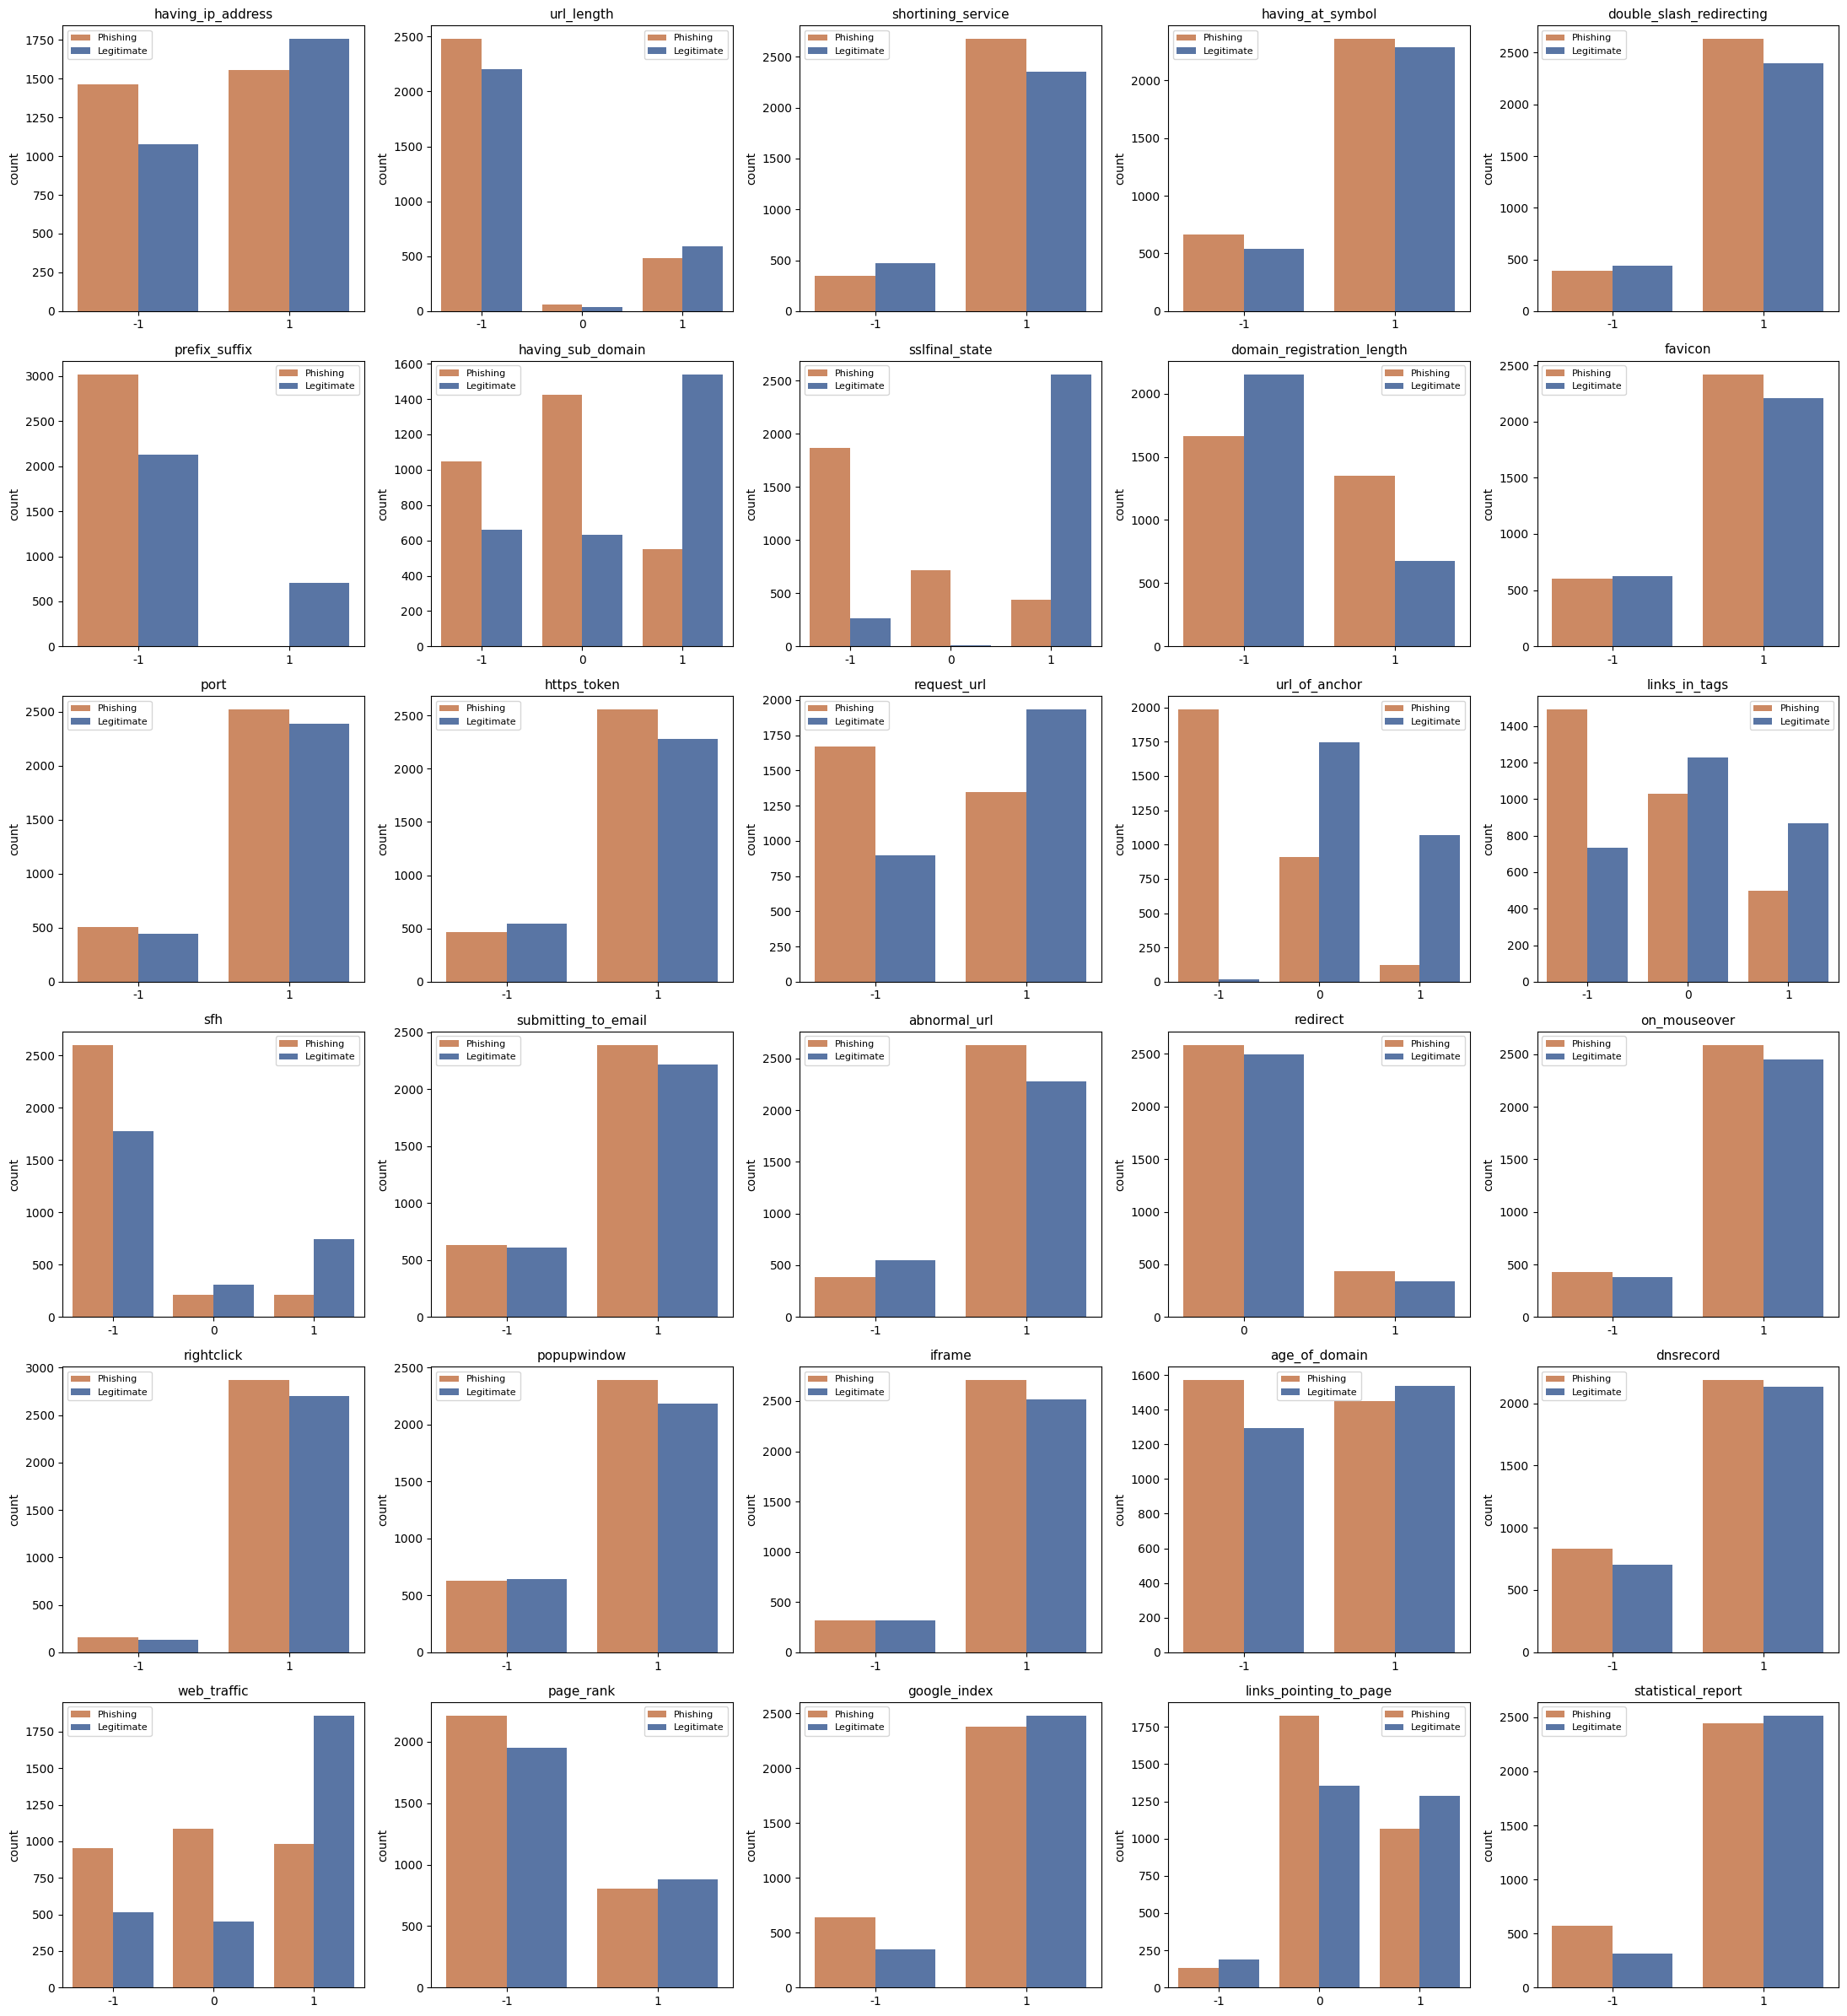

In [9]:
fig, axes = plt.subplots(6, 5, figsize=(22, 24))
plot_df = df.copy()
plot_df['class'] = plot_df[TARGET].map({-1: 'Phishing', 1: 'Legitimate'})

for ax, col in zip(axes.flat, FEATURES):
    sns.countplot(data=plot_df, x=col, hue='class', ax=ax,
                  hue_order=['Phishing', 'Legitimate'],
                  palette={'Phishing': '#DD8452', 'Legitimate': '#4C72B0'})
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/feature_distributions_by_class.png', dpi=120)
plt.show()

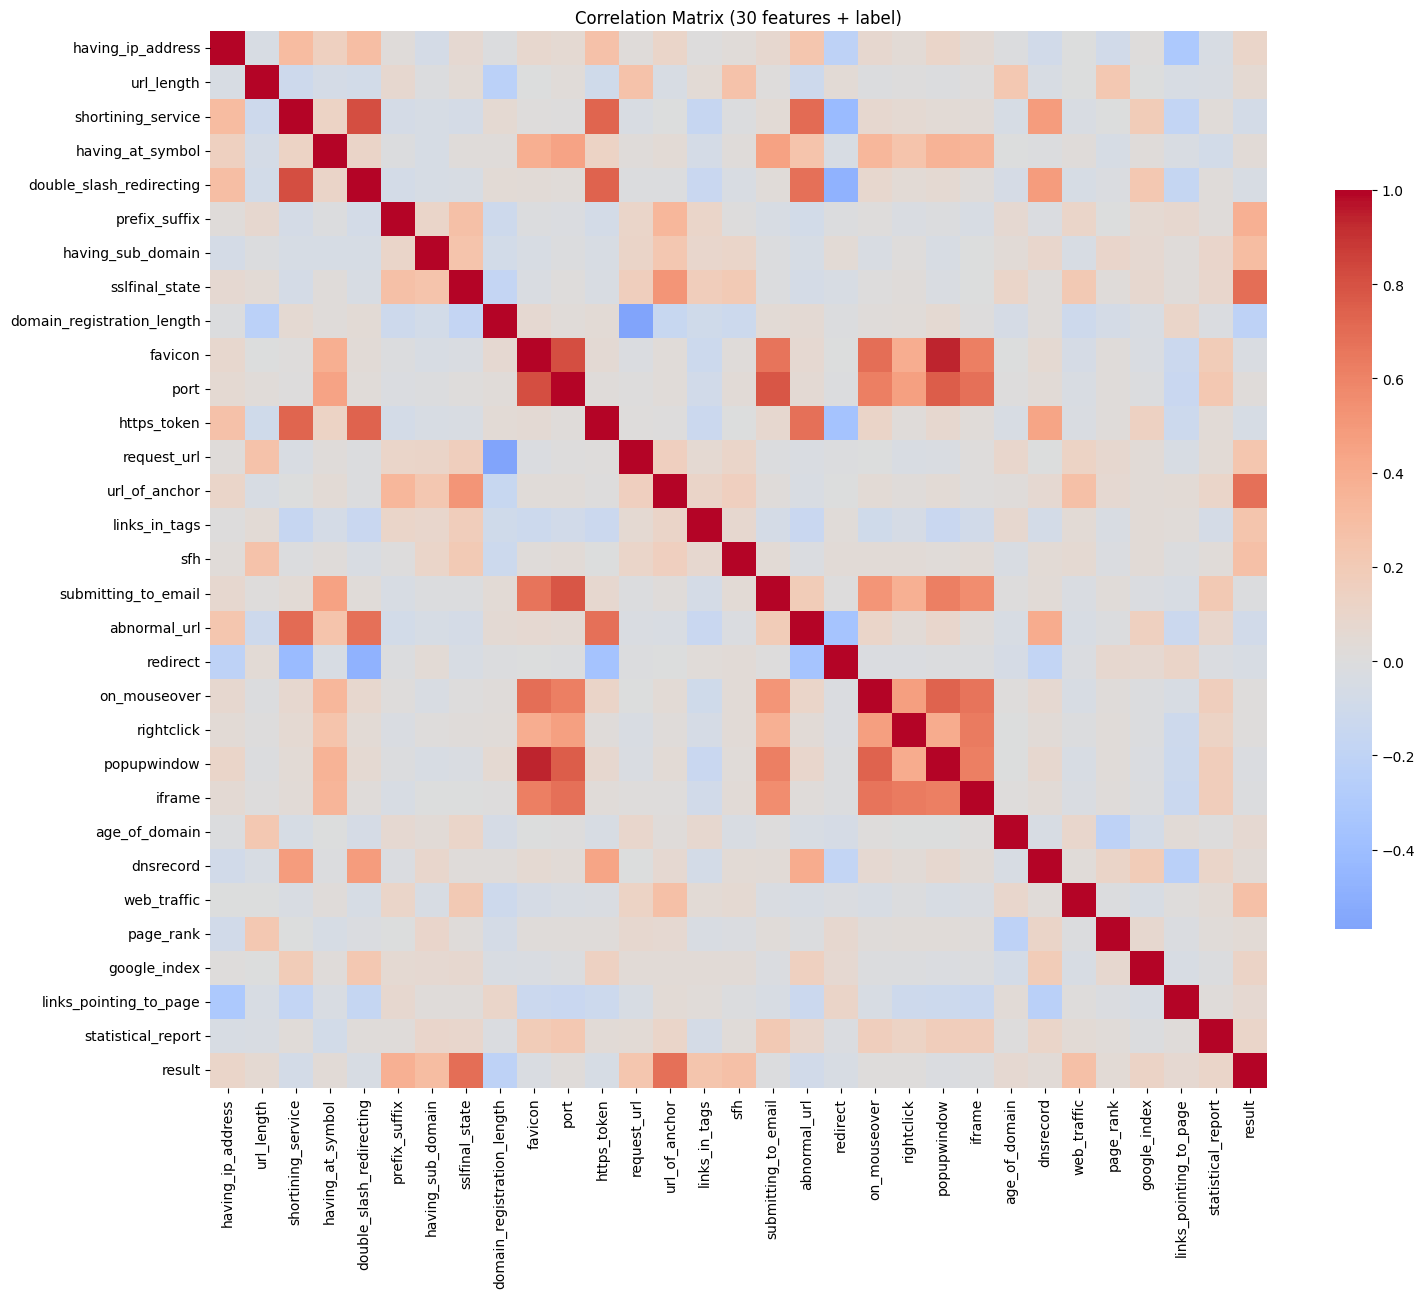

sslfinal_state                0.693228
url_of_anchor                 0.679125
prefix_suffix                 0.381134
having_sub_domain             0.296214
web_traffic                   0.281709
sfh                           0.281131
links_in_tags                 0.243864
request_url                   0.237778
domain_registration_length   -0.218623
google_index                  0.118217
Name: result, dtype: float64


In [10]:
corr = df.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True,
            cbar_kws={'shrink': 0.7})
plt.title('Correlation Matrix (30 features + label)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/correlation_heatmap.png', dpi=150)
plt.show()

# Features most correlated with the label
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(10))